<a href="https://colab.research.google.com/github/Daudi-Zacharia/msc-thesis/blob/main/segmentation/clean_notebooks/quantitative_d2_segmentation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# INFO

**No-reference quality analysis of the U-Net lung masks on D2 (4200 images).**

D2 has no ground-truth masks, so every predicted mask is judged by its own shape
rather than against a reference. A correct lung mask is roughly two solid blobs;
a failed one breaks into scattered fragments. This notebook turns "TB images
segment worse than Normal images" into a measured, testable claim.

Pipeline, model and transforms are the ones from **Part 5: UNET 2** of
`Segmentation_Unet_Full.ipynb` — same `seg_unet_2.pth` checkpoint, same
224x224 resize, same ImageNet normalization. Nothing about the segmentation is
new here; only the measurement is.

**Contents**

1. Configuration and imports
2. Data setup — the whole of D2 in a flat `Images/{tb,no_tb}` folder
3. Per-mask metrics (`n_components`, `largest2_frac`, `total_area_frac`, `is_clean`)
4. U-Net loading and mask generation over all 4200 images
5. Aggregation — summary table, outliers
6. Statistical test — Mann-Whitney U, TB vs Normal
7. Qualitative figures — 2 examples per class, saved for the manuscript

# 1. CONFIGURATION AND IMPORTS

In [1]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
!pip install kagglehub -q
!pip install openpyxl -q

In [3]:
import os
import shutil
import time

import numpy as np
import pandas as pd
import PIL
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision.transforms import v2 as T

from scipy import ndimage
from scipy.stats import mannwhitneyu

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {device}')

# --- paths -----------------------------------------------------------------
path_segmentation = '/content/drive/MyDrive/MSc Data Science/Thesis/Codes/segmentation'
path_model = os.path.join(path_segmentation, 'seg_unet_2.pth')

IMAGES_DIR = './Images'                 # flat folder: Images/tb, Images/no_tb
FIG_DIR = './figures_d2_mask_quality'   # where the manuscript figures are written

# --- analysis settings -----------------------------------------------------
BATCH_SIZE = 64
PROGRESS_EVERY = 5                      # print progress every N batches

# a mask counts as "clean" if it is at most two blobs that hold essentially
# all of the mask area
CLEAN_MAX_COMPONENTS = 2
CLEAN_MIN_LARGEST2 = 0.95

CLASS_NAMES = {0: 'Normal', 1: 'TB'}    # matches the no_tb / tb folders

os.makedirs(FIG_DIR, exist_ok=True)

Device: cuda


# 2. DATA SETUP

`create_images_folder_4200` is the function from `Segmentation_Unet_Full.ipynb`
(Part 5, "4200 dataset"). It copies the whole dataset into a flat
`Images/{tb,no_tb}` folder — no train/val/test split, because this analysis
covers all 4200 images and only needs the class label.

The vestigial 80/10/10 ratio block from the original has been dropped: it only
printed split sizes and never touched the folders it creates, so keeping it here
would print numbers that have nothing to do with this analysis.

In [4]:
import kagglehub

path_rahman = kagglehub.dataset_download("tawsifurrahman/tuberculosis-tb-chest-xray-dataset")
print("Path to dataset files:", path_rahman)

100%|██████████| 663M/663M [00:38<00:00, 18.2MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/tawsifurrahman/tuberculosis-tb-chest-xray-dataset/versions/3


In [5]:
def create_images_folder_4200(path, base_dir=IMAGES_DIR):
    """Copies every D2 image into base_dir/{tb,no_tb}. Returns the two id lists."""

    tb_md = pd.read_excel(os.path.join(path, 'TB_Chest_Radiography_Database',
                                       'Tuberculosis.metadata.xlsx'))
    no_tb_md = pd.read_excel(os.path.join(path, 'TB_Chest_Radiography_Database',
                                          'Normal.metadata.xlsx'))

    img_id1 = list(tb_md['FILE NAME'])
    img_id0 = list(no_tb_md['FILE NAME'])

    print(f'# of TB images: {len(img_id1)}')
    print(f'# of Normal images: {len(img_id0)}')
    print(f'Total: {len(img_id1) + len(img_id0)}')

    for klas in ['tb', 'no_tb']:
        os.makedirs(os.path.join(base_dir, klas), exist_ok=True)

    path_tb_images = os.path.join(path, 'TB_Chest_Radiography_Database', 'Tuberculosis')
    path_no_tb_images = os.path.join(path, 'TB_Chest_Radiography_Database', 'Normal')

    print('Copying images...')
    for i in img_id1:
        str_i = str(i) + '.png'
        shutil.copy(src=os.path.join(path_tb_images, str_i),
                    dst=os.path.join(base_dir, 'tb', str_i))

    for i in img_id0:
        str_i = str(i) + '.png'
        shutil.copy(src=os.path.join(path_no_tb_images, str_i),
                    dst=os.path.join(base_dir, 'no_tb', str_i))

    print(f'Successfully created {base_dir}/tb and {base_dir}/no_tb')
    return img_id1, img_id0


img_id1, img_id0 = create_images_folder_4200(path_rahman)

# sanity check on the folder contents
for klas in ['tb', 'no_tb']:
    print(f'{klas:>6}: {len(os.listdir(os.path.join(IMAGES_DIR, klas)))} files')

# of TB images: 700
# of Normal images: 3500
Total: 4200
Copying images...
Successfully created ./Images/tb and ./Images/no_tb
    tb: 700 files
 no_tb: 3500 files


# 3. PER-MASK METRICS

Each predicted binary mask (1 = lung) is reduced to four numbers:

| metric | meaning |
|---|---|
| `n_components` | connected components, 8-connectivity |
| `largest2_frac` | area of the two biggest components / total mask area |
| `total_area_frac` | mask pixels / image pixels |

A perfect lung mask scores `n_components = 2`, `largest2_frac = 1.0` and total_area_frac is reasonable (>5%). Empty masks have no shape to measure, so
`largest2_frac` is `NaN` and they are counted separately.

In [6]:
# 8-connectivity: pixels touching at a corner count as the same component.
# (scipy's default is 4-connectivity, which would inflate n_components.)
CONNECTIVITY_8 = np.ones((3, 3), dtype=int)


def mask_metrics(mask):
    """Shape metrics for one predicted binary mask.

    mask: 2-D array, non-zero where the model predicted lung.
    Returns a dict with n_components, largest2_frac, total_area_frac, is_clean.
    """
    total_px = mask.size
    area = int(np.count_nonzero(mask))

    # empty mask: no components, and largest2_frac would be 0/0
    if area == 0:
        return {'n_components': 0,
                'largest2_frac': np.nan,
                'total_area_frac': 0.0,
                'is_clean': False}

    labelled, n_components = ndimage.label(mask, structure=CONNECTIVITY_8)

    # component sizes, dropping label 0 (background)
    sizes = np.bincount(labelled.ravel())[1:]
    # with a single component this sums to the whole mask, giving exactly 1.0
    largest2_frac = float(np.sort(sizes)[-2:].sum() / area)

    return {'n_components': int(n_components),
            'largest2_frac': largest2_frac,
            'total_area_frac': area / total_px,
            'is_clean': bool(n_components <= CLEAN_MAX_COMPONENTS
                             and largest2_frac >= CLEAN_MIN_LARGEST2)}

In [7]:
# quick self-check on hand-made masks, so a silent change in behaviour is visible
_two_blobs = np.zeros((10, 10), dtype=np.uint8)
_two_blobs[1:4, 1:4] = 1        # two well-separated 3x3 blobs, like a good
_two_blobs[6:9, 6:9] = 1        # lung mask: 2 components, largest2_frac 1.0

_speckled = _two_blobs.copy()
_speckled[0, 9] = 1             # one stray pixel: 3 components, frac < 1.0

print('two clean blobs :', mask_metrics(_two_blobs))
print('with one speck  :', mask_metrics(_speckled))
print('empty mask      :', mask_metrics(np.zeros((10, 10), dtype=np.uint8)))

two clean blobs : {'n_components': 2, 'largest2_frac': 1.0, 'total_area_frac': 0.18, 'is_clean': True}
with one speck  : {'n_components': 3, 'largest2_frac': 0.9473684210526315, 'total_area_frac': 0.19, 'is_clean': False}
empty mask      : {'n_components': 0, 'largest2_frac': nan, 'total_area_frac': 0.0, 'is_clean': False}


# 4. U-NET LOADING AND MASK GENERATION

Architecture, checkpoint and preprocessing are copied from Part 5 of
`Segmentation_Unet_Full.ipynb`. Masks are scored as they come off the GPU rather
than written to disk — the analysis only needs the four numbers per image.

In [8]:
from torchvision.models import vgg16_bn


# CONV AND UP_CONV LAYERS
def conv(in_channels, out_channels):
    return nn.Sequential(
        nn.Conv2d(in_channels, out_channels, kernel_size=3, stride=1, padding=1),
        nn.BatchNorm2d(out_channels),
        nn.ReLU(inplace=True)
    )


def up_conv(in_channels, out_channels):
    return nn.Sequential(
        nn.ConvTranspose2d(in_channels, out_channels, kernel_size=2, stride=2),
        nn.BatchNorm2d(out_channels),
        nn.ReLU(inplace=True)
    )


class UNet(nn.Module):
    """VGG16-BN encoder with a symmetric decoder and skip connections."""

    def __init__(self, num_classes=2):
        super().__init__()

        self.encoder = vgg16_bn(weights='DEFAULT').features

        self.block1 = nn.Sequential(*self.encoder[:6])
        self.block2 = nn.Sequential(*self.encoder[6:13])
        self.block3 = nn.Sequential(*self.encoder[13:20])
        self.block4 = nn.Sequential(*self.encoder[20:27])
        self.block5 = nn.Sequential(*self.encoder[27:34])

        self.bottleneck = nn.Sequential(*self.encoder[34:])
        self.conv_bottleneck = conv(512, 1024)   # widen before upsampling

        self.up_conv6 = up_conv(1024, 512)
        self.conv6 = conv(512 + 512, 512)
        self.up_conv7 = up_conv(512, 256)
        self.conv7 = conv(256 + 512, 256)
        self.up_conv8 = up_conv(256, 128)
        self.conv8 = conv(128 + 256, 128)
        self.up_conv9 = up_conv(128, 64)
        self.conv9 = conv(64 + 128, 64)
        self.up_conv10 = up_conv(64, 32)
        self.conv10 = conv(32 + 64, 32)

        self.conv11 = nn.Conv2d(32, num_classes, kernel_size=1)

    def forward(self, x):
        # encoder, keeping each stage for the skip connections
        block1 = self.block1(x)          # (64, 224, 224)
        block2 = self.block2(block1)     # (128, 112, 112)
        block3 = self.block3(block2)     # (256, 56, 56)
        block4 = self.block4(block3)     # (512, 28, 28)
        block5 = self.block5(block4)     # (512, 14, 14)

        bottleneck = self.bottleneck(block5)      # (512, 7, 7)
        x = self.conv_bottleneck(bottleneck)      # (1024, 7, 7)

        # decoder: upsample, concatenate the matching encoder stage, convolve
        x = self.conv6(torch.cat([self.up_conv6(x), block5], dim=1))
        x = self.conv7(torch.cat([self.up_conv7(x), block4], dim=1))
        x = self.conv8(torch.cat([self.up_conv8(x), block3], dim=1))
        x = self.conv9(torch.cat([self.up_conv9(x), block2], dim=1))
        x = self.conv10(torch.cat([self.up_conv10(x), block1], dim=1))

        return self.conv11(x)            # (num_classes, 224, 224)


model = UNet(num_classes=2)
model.load_state_dict(torch.load(path_model, map_location=device))
model.to(device)
model.eval()
print(f'Loaded U-Net checkpoint: {path_model}')

Downloading: "https://download.pytorch.org/models/vgg16_bn-6c64b313.pth" to /root/.cache/torch/hub/checkpoints/vgg16_bn-6c64b313.pth


100%|██████████| 528M/528M [00:06<00:00, 83.2MB/s]


Loaded U-Net checkpoint: /content/drive/MyDrive/MSc Data Science/Thesis/Codes/segmentation/seg_unet_2.pth


In [9]:
class ROI(Dataset):
    """Yields (original, normalized, label, filename) for every image in root_dir.

    Same transforms the segmentation model was evaluated with: resize to
    224x224, scale to [0,1], ImageNet normalization. The un-normalized copy is
    kept for display only.
    """

    def __init__(self, root_dir):
        self.transforms_norm = T.Compose([
            T.Resize((224, 224)),
            T.ToImage(),                              # PIL -> tv2 tensor
            T.ToDtype(torch.float32, scale=True),     # scales to [0, 1]
            T.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
        ])

        self.transforms_orig = T.Compose([
            T.Resize((224, 224)),
            T.ToImage(),
            T.ToDtype(torch.float32, scale=True),
        ])

        self.root_dir = root_dir

        im_id0 = os.listdir(os.path.join(self.root_dir, 'no_tb'))
        im_id1 = os.listdir(os.path.join(self.root_dir, 'tb'))

        # (folder, filename, label)
        self.im_data = [('no_tb', f, 0) for f in im_id0]
        self.im_data += [('tb', f, 1) for f in im_id1]

    def __len__(self):
        return len(self.im_data)

    def __getitem__(self, idx):
        folder, im_name, label = self.im_data[idx]
        image = PIL.Image.open(os.path.join(self.root_dir, folder, im_name)).convert('RGB')

        return (self.transforms_orig(image),
                self.transforms_norm(image),
                torch.tensor(label).long(),
                im_name)


td = ROI(IMAGES_DIR)
dl = DataLoader(td, batch_size=BATCH_SIZE)

# the area fractions below are relative to this resolution, so state it
MASK_H, MASK_W = td[0][1].shape[-2:]
print(f'Number of images : {len(td)}')
print(f'Number of batches: {len(dl)}')
print(f'Mask resolution  : {MASK_H} x {MASK_W}  ({MASK_H * MASK_W} pixels per mask)')

Number of images : 4200
Number of batches: 66
Mask resolution  : 224 x 224  (50176 pixels per mask)


In [10]:
def generate_mask_metrics(model, data_loader, device):
    """Runs the U-Net over the whole dataset and scores each predicted mask.

    Masks are measured batch by batch and discarded, so memory stays flat.
    Returns a per-image DataFrame.
    """
    model.to(device)
    model.eval()

    records = []
    start_time = time.time()
    print(f'Segmenting {len(data_loader.dataset)} images in {len(data_loader)} batches...')

    with torch.no_grad():
        for batch_idx, (_, images_norm, labels, names) in enumerate(data_loader):

            logits = model(images_norm.to(device))
            # class 1 = lung; argmax gives the same binary mask used downstream
            pred_masks = logits.argmax(dim=1).cpu().numpy().astype(np.uint8)

            for i in range(len(pred_masks)):
                records.append({
                    'filename': names[i],
                    'class': CLASS_NAMES[int(labels[i])],
                    **mask_metrics(pred_masks[i]),
                })

            if (batch_idx + 1) % PROGRESS_EVERY == 0:
                done = len(records)
                elapsed = (time.time() - start_time) / 60
                print(f'  batch {batch_idx + 1:>3}/{len(data_loader)} | '
                      f'{done:>4}/{len(data_loader.dataset)} images | '
                      f'{elapsed:.2f} min elapsed')

    total_time = (time.time() - start_time) / 60
    print(f'Done! Total inference time: {total_time:.2f} minutes')

    return pd.DataFrame(records)


# full per-image results, kept around for outlier inspection and spot-checks
df_masks = generate_mask_metrics(model, dl, device)

print()
print(f'Rows: {len(df_masks)}')
display(df_masks.head())

Segmenting 4200 images in 66 batches...
  batch   5/66 |  320/4200 images | 0.15 min elapsed
  batch  10/66 |  640/4200 images | 0.29 min elapsed
  batch  15/66 |  960/4200 images | 0.42 min elapsed
  batch  20/66 | 1280/4200 images | 0.61 min elapsed
  batch  25/66 | 1600/4200 images | 0.75 min elapsed
  batch  30/66 | 1920/4200 images | 0.88 min elapsed
  batch  35/66 | 2240/4200 images | 1.03 min elapsed
  batch  40/66 | 2560/4200 images | 1.16 min elapsed
  batch  45/66 | 2880/4200 images | 1.31 min elapsed
  batch  50/66 | 3200/4200 images | 1.44 min elapsed
  batch  55/66 | 3520/4200 images | 1.58 min elapsed
  batch  60/66 | 3840/4200 images | 1.72 min elapsed
  batch  65/66 | 4160/4200 images | 1.85 min elapsed
Done! Total inference time: 1.86 minutes

Rows: 4200


,filename,class,n_components,largest2_frac,total_area_frac,is_clean
0,Normal-3230.png,Normal,2,1.000000,0.219248,True
1,Normal-2612.png,Normal,2,1.000000,0.249741,True
2,Normal-1322.png,Normal,2,1.000000,0.288026,True
3,Normal-1153.png,Normal,2,1.000000,0.215063,True
4,Normal-1659.png,Normal,4,0.981095,0.170779,False


## Exploration of Normal Images

In [11]:
df_masks[df_masks['class']=='Normal'].describe().round(3)

,n_components,largest2_frac,total_area_frac
count,3500.000,3499.000,3500.000
mean,2.687,0.997,0.246
std,1.275,0.012,0.061
min,0.000,0.692,0.000
25%,2.000,0.999,0.209
50%,2.000,1.000,0.246
75%,3.000,1.000,0.287
max,20.000,1.000,0.448


In [42]:
df_masks[(df_masks['class'] == 'Normal') & (df_masks['n_components'] != 0)].describe().round(6)

,n_components,largest2_frac,total_area_frac
count,3499.000000,3499.000000,3499.000000
mean,2.688197,0.997111,0.245983
std,1.274146,0.011721,0.060999
min,1.000000,0.691963,0.000199
25%,2.000000,0.998989,0.208785
50%,2.000000,1.000000,0.246173
75%,3.000000,1.000000,0.286890
max,20.000000,1.000000,0.447784


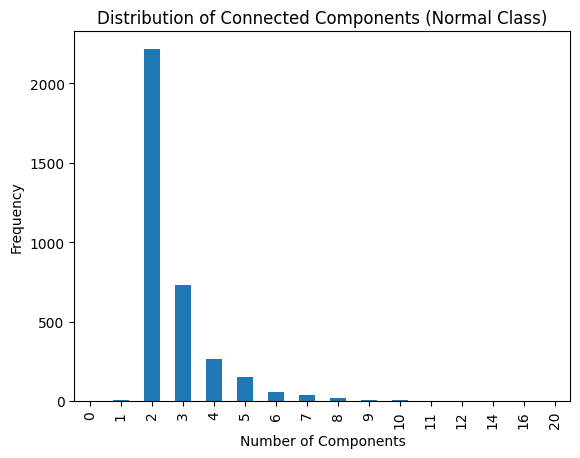

In [34]:
# Bar graph of component counts for Normal images
df_masks[df_masks['class'] == 'Normal']['n_components'].value_counts().sort_index().plot(kind='bar')
plt.title('Distribution of Connected Components (Normal Class)')
plt.xlabel('Number of Components')
plt.ylabel('Frequency')
plt.show()

In [25]:
# Just 1 normal image produced an empty mask. I want to see this image. I will also visualize the 20 components image

df_masks[df_masks['class']=='Normal'][df_masks['n_components'] == 0]

/tmp/ipykernel_802/1080381410.py:1: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  df_masks[df_masks['class']=='Normal'][df_masks['n_components'] == 0]


,filename,class,n_components,largest2_frac,total_area_frac,is_clean
2798,Normal-1503.png,Normal,0,NaN,0.0,False


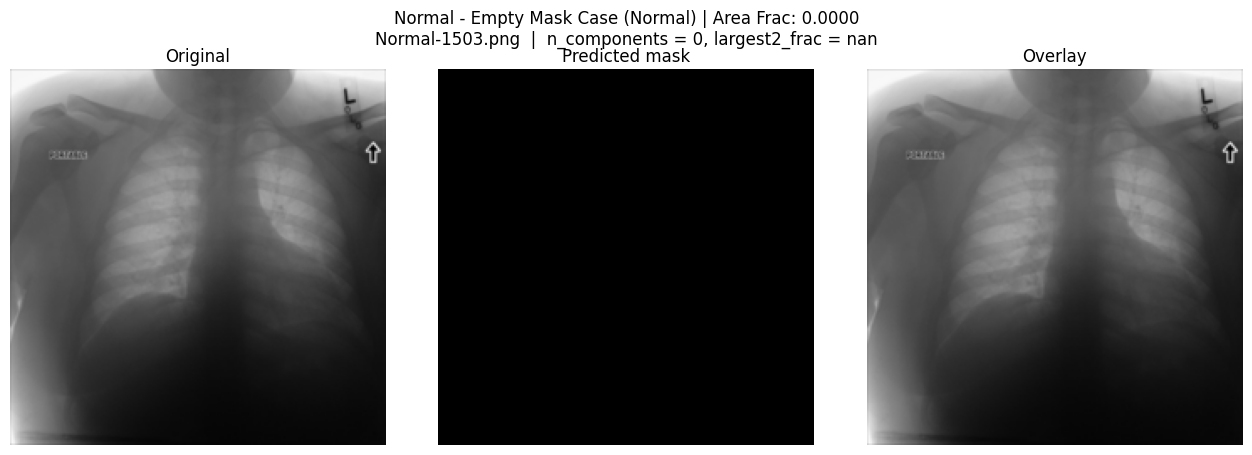

saved -> ./figures_d2_mask_quality/normal_empty_mask.png


'./figures_d2_mask_quality/normal_empty_mask.png'

In [45]:
row_empty_normal = df_masks[(df_masks['class'] == 'Normal') & (df_masks['n_components'] == 0)].iloc[0]
render_example(row_empty_normal, f'Empty Mask Case (Normal) | Area Frac: {row_empty_normal["total_area_frac"]:.4f}', os.path.join(FIG_DIR, 'normal_empty_mask.png'))

In [ ]:
# Identify all Normal images with low area fraction (<= 0.1)
# It is difficult to establish a value of total area frac that will be a good threshold for discriminating between bad and good predictions

normal_low_area = df_masks[(df_masks['class'] == 'Normal') & (df_masks['total_area_frac'] <= 0.1)]

print(f"Found {len(normal_low_area)} Normal image(s) with total_area_frac <= 0.1.")

for _, row in normal_low_area.iterrows():
    # Include area frac in the tag for the title
    title_tag = f"Low Area Case (Normal) | Area Frac: {row['total_area_frac']:.4f}"
    render_example(row, title_tag, os.path.join(FIG_DIR, f"low_area_normal_{row['filename']}"))

In [36]:
df_masks[df_masks['class']=='Normal'][df_masks['n_components'] == 20]

/tmp/ipykernel_802/545739784.py:1: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  df_masks[df_masks['class']=='Normal'][df_masks['n_components'] == 20]


,filename,class,n_components,largest2_frac,total_area_frac,is_clean
86,Normal-3106.png,Normal,20,0.996599,0.269591,False


In [ ]:
row_empty_normal = df_masks[(df_masks['class'] == 'Normal') & (df_masks['n_components'] == 20)].iloc[0]
render_example(row_empty_normal, 'Empty Mask Case (Normal)', os.path.join(FIG_DIR, 'normal_empty_mask.png'))

## Exploration of TB Images

In [37]:
df_masks[df_masks['class']=='TB'].describe().round(3)

,n_components,largest2_frac,total_area_frac
count,700.000,564.000,700.000
mean,4.117,0.977,0.183
std,3.996,0.053,0.138
min,0.000,0.511,0.000
25%,2.000,0.986,0.024
50%,3.000,0.999,0.207
75%,6.000,1.000,0.295
max,28.000,1.000,0.480


In [38]:
df_masks[(df_masks['class'] == 'TB') & (df_masks['n_components'] != 0)].describe().round(3)

,n_components,largest2_frac,total_area_frac
count,564.00,564.000,564.000
mean,5.11,0.977,0.227
std,3.84,0.053,0.116
min,1.00,0.511,0.000
25%,2.00,0.986,0.141
50%,4.00,0.999,0.244
75%,7.00,1.000,0.316
max,28.00,1.000,0.480


In [26]:
# 136 TB Images produced an empty mask

df_masks[df_masks['class']=='TB'][df_masks['n_components'] == 0]

/tmp/ipykernel_802/1144517214.py:1: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  df_masks[df_masks['class']=='TB'][df_masks['n_components'] == 0]


,filename,class,n_components,largest2_frac,total_area_frac,is_clean
3501,Tuberculosis-606.png,TB,0,NaN,0.0,False
3506,Tuberculosis-295.png,TB,0,NaN,0.0,False
3511,Tuberculosis-467.png,TB,0,NaN,0.0,False
3512,Tuberculosis-557.png,TB,0,NaN,0.0,False
3522,Tuberculosis-372.png,TB,0,NaN,0.0,False
...,...,...,...,...,...,...
4164,Tuberculosis-425.png,TB,0,NaN,0.0,False
4173,Tuberculosis-399.png,TB,0,NaN,0.0,False
4181,Tuberculosis-210.png,TB,0,NaN,0.0,False
4185,Tuberculosis-396.png,TB,0,NaN,0.0,False


In [ ]:
# Identify all TB images with empty masks
tb_empty_masks = df_masks[(df_masks['class'] == 'TB') & (df_masks['n_components'] == 0)]

# Sample 20 randomly
sample_20 = tb_empty_masks.sample(n=min(20, len(tb_empty_masks)), random_state=42)

print(f"Visualizing {len(sample_20)} random TB images with empty masks...")

for _, row in sample_20.iterrows():
    render_example(row, "Empty Mask TB Sample", os.path.join(FIG_DIR, f"empty_tb_{row['filename']}"))

# 5. STATISTICAL TEST

Component counts are small integers with a long right tail, so a t-test would be
the wrong tool. The Mann-Whitney U test compares the two distributions by rank
and assumes nothing about their shape. The two-sided p value is given.

In [48]:
def mannwhitney_report_simple(df, column):
    """Mann-Whitney U on `column`, TB vs Normal (two-sided), excluding empty masks."""
    # Exclude rows where column is NaN or n_components is 0
    g = df.dropna(subset=[column])
    g = g[g['n_components'] > 0]

    tb = g.loc[g['class'] == 'TB', column]
    normal = g.loc[g['class'] == 'Normal', column]

    u_stat, p_val = mannwhitneyu(tb, normal, alternative='two-sided')

    print(f'--- {column} (Non-Empty Only): TB (n={len(tb)}) vs Normal (n={len(normal)}) ---')
    print(f'median  TB = {tb.median():.4f} | Normal = {normal.median():.4f}')
    print(f'mean    TB = {tb.mean():.4f} | Normal = {normal.mean():.4f}')
    print(f'two-sided Mann-Whitney U: U = {u_stat:.1f}, p = {p_val:.3e}')
    print()

    return {'metric': column, 'U_stat': u_stat, 'p_value': p_val}

# Compute two-tailed test for number of components (excluding empty masks)
stats_components = mannwhitney_report_simple(df_masks, 'n_components')

display(pd.DataFrame([stats_components]).set_index('metric'))

--- n_components (Non-Empty Only): TB (n=564) vs Normal (n=3499) ---
median  TB = 4.0000 | Normal = 2.0000
mean    TB = 5.1099 | Normal = 2.6882
two-sided Mann-Whitney U: U = 1419548.0, p = 8.876e-79



,U_stat,p_value
metric,,
n_components,1419548.0,8.875760e-79
